In [6]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import time

from tensorflow.keras import layers, models
from tensorflow.keras.datasets import mnist

(x_train_all, y_train_all), (x_test_all, y_test_all) = mnist.load_data()

# Select only digits 0 and 1
train_mask = np.isin(y_train_all, [0, 1])
test_mask = np.isin(y_test_all, [0, 1])

x_train = x_train_all[train_mask][:80]
y_train = y_train_all[train_mask][:80]

x_test = x_test_all[test_mask][:20]
y_test = y_test_all[test_mask][:20]

print("Training Images:", x_train.shape)
print("Testing Images:", x_test.shape)

Training Images: (80, 28, 28)
Testing Images: (20, 28, 28)


In [7]:
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

x_train = np.expand_dims(x_train, axis=-1)
x_test = np.expand_dims(x_test, axis=-1)

print("Train:", x_train.shape)
print("Test:", x_test.shape)

Train: (80, 28, 28, 1)
Test: (20, 28, 28, 1)


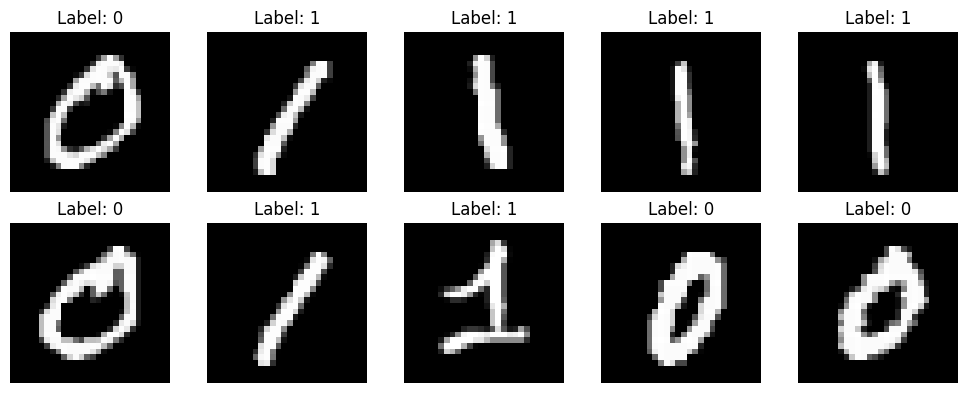

In [8]:
plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i+1)
    plt.imshow(x_train[i].squeeze(), cmap='gray')
    plt.title(f"Label: {y_train[i]}")
    plt.axis('off')

plt.tight_layout()
plt.show()

In [9]:
x_val = x_train[:16]
y_val = y_train[:16]

x_train_new = x_train[16:]
y_train_new = y_train[16:]

print("Training:", x_train_new.shape)
print("Validation:", x_val.shape)
print("Testing:", x_test.shape)

Training: (64, 28, 28, 1)
Validation: (16, 28, 28, 1)
Testing: (20, 28, 28, 1)


In [10]:
cnn_model = models.Sequential([
    layers.Input(shape=(28, 28, 1)),

    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(64, activation='relu'),
    layers.Dropout(0.3),

    layers.Dense(1, activation='sigmoid')
])

cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121,345 (474.00 KB)

 Trainable params: 121,345 (474.00 KB)

 Non-trainable params: 0 (0.00 B)

In [11]:
cnn_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [12]:
start_time = time.time()

cnn_history = cnn_model.fit(
    x_train_new,
    y_train_new,
    epochs=5,
    batch_size=8,
    validation_data=(x_val, y_val)
)

cnn_time = time.time() - start_time

print("CNN Training Time:", cnn_time)

Epoch 1/5
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step - accuracy: 0.7969 - loss: 0.5097 - val_accuracy: 0.9375 - val_loss: 0.2962
Epoch 2/5
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.9844 - loss: 0.1343 - val_accuracy: 0.9375 - val_loss: 0.1106
Epoch 3/5
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.9844 - loss: 0.0433 - val_accuracy: 0.9375 - val_loss: 0.0659
Epoch 4/5
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 1.0000 - loss: 0.0143 - val_accuracy: 1.0000 - val_loss: 0.0138
Epoch 5/5
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 1.0000 - loss: 0.0093 - val_accuracy: 1.0000 - val_loss: 0.0218
CNN Training Time: 2.345470666885376


In [13]:
cnn_loss, cnn_accuracy = cnn_model.evaluate(x_test, y_test)

print("CNN Test Accuracy:", cnn_accuracy)
print("CNN Test Loss:", cnn_loss)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 274ms/step - accuracy: 1.0000 - loss: 2.1170e-04
CNN Test Accuracy: 1.0
CNN Test Loss: 0.0002116969262715429


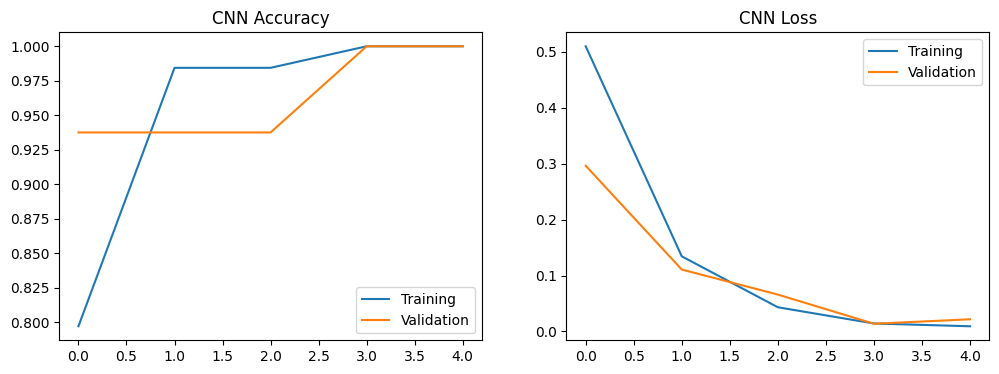

In [14]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(cnn_history.history['accuracy'], label='Training')
plt.plot(cnn_history.history['val_accuracy'], label='Validation')
plt.title('CNN Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(cnn_history.history['loss'], label='Training')
plt.plot(cnn_history.history['val_loss'], label='Validation')
plt.title('CNN Loss')
plt.legend()

plt.show()

In [16]:
IMG_SIZE = 96

def prepare_eff_images(images):
    images = tf.convert_to_tensor(images, dtype=tf.float32)

    images = images * 255.0

    images = tf.image.grayscale_to_rgb(images)

    images = tf.image.resize(images, (IMG_SIZE, IMG_SIZE))

    return images

x_train_eff = prepare_eff_images(x_train_new)
x_val_eff = prepare_eff_images(x_val)
x_test_eff = prepare_eff_images(x_test)

print(x_train_eff.shape)
print(x_val_eff.shape)
print(x_test_eff.shape)

(64, 96, 96, 3)
(16, 96, 96, 3)
(20, 96, 96, 3)


In [17]:
base_model = tf.keras.applications.EfficientNetB0(
    weights='imagenet',
    include_top=False,
    input_shape=(96, 96, 3)
)

base_model.trainable = False

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


In [18]:
efficient_model = models.Sequential([
    layers.Input(shape=(96, 96, 3)),

    base_model,

    layers.GlobalAveragePooling2D(),

    layers.Dropout(0.3),

    layers.Dense(1, activation='sigmoid')
])

efficient_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 3, 3, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,050,852 (15.45 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [19]:
efficient_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [21]:
y_val_eff = y_val

In [22]:
start_time = time.time()

efficient_history = efficient_model.fit(
    x_train_eff,
    y_train_new,
    epochs=3,
    batch_size=8,
    validation_data=(x_val_eff, y_val_eff)
)

efficient_time = time.time() - start_time

print("EfficientNet Training Time:", efficient_time)

Epoch 1/3
8/8 ━━━━━━━━━━━━━━━━━━━━ 14s 662ms/step - accuracy: 0.7812 - loss: 0.5103 - val_accuracy: 1.0000 - val_loss: 0.3871
Epoch 2/3
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 112ms/step - accuracy: 0.9844 - loss: 0.3071 - val_accuracy: 1.0000 - val_loss: 0.2386
Epoch 3/3
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 112ms/step - accuracy: 0.9844 - loss: 0.2236 - val_accuracy: 1.0000 - val_loss: 0.1506
EfficientNet Training Time: 15.57282304763794


In [23]:
efficient_loss, efficient_accuracy = efficient_model.evaluate(
    x_test_eff, y_test
)

print("EfficientNet Test Accuracy:", efficient_accuracy)
print("EfficientNet Test Loss:", efficient_loss)

1/1 ━━━━━━━━━━━━━━━━━━━━ 9s 9s/step - accuracy: 1.0000 - loss: 0.1478
EfficientNet Test Accuracy: 1.0
EfficientNet Test Loss: 0.1477794349193573


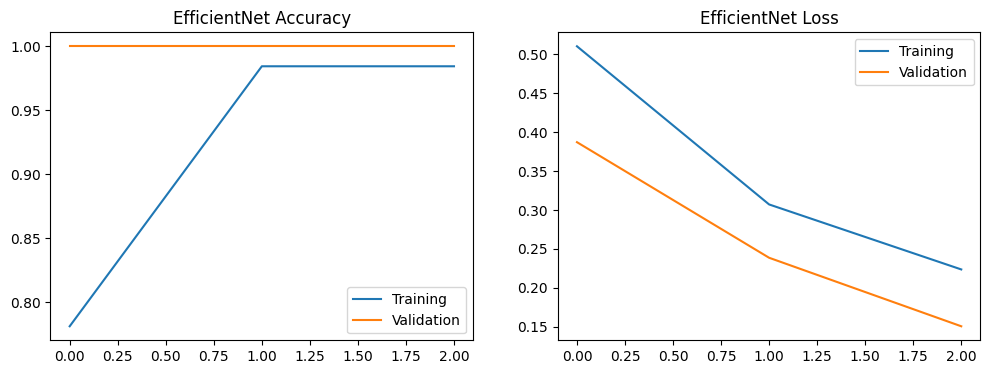

In [24]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(efficient_history.history['accuracy'], label='Training')
plt.plot(efficient_history.history['val_accuracy'], label='Validation')
plt.title('EfficientNet Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(efficient_history.history['loss'], label='Training')
plt.plot(efficient_history.history['val_loss'], label='Validation')
plt.title('EfficientNet Loss')
plt.legend()

plt.show()

In [25]:
results = pd.DataFrame({
    'Model': ['CNN', 'EfficientNetB0'],
    'Test Accuracy': [cnn_accuracy, efficient_accuracy],
    'Test Loss': [cnn_loss, efficient_loss],
    'Training Time (seconds)': [cnn_time, efficient_time]
})

results

,Model,Test Accuracy,Test Loss,Training Time (seconds)
0,CNN,1.0,0.000212,2.345471
1,EfficientNetB0,1.0,0.147779,15.572823


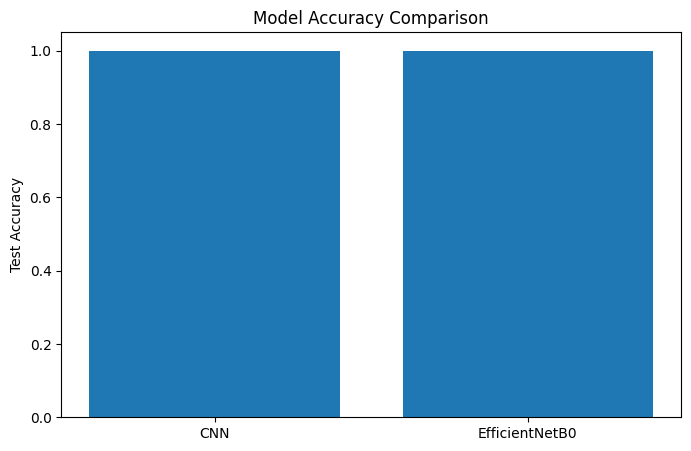

In [26]:
plt.figure(figsize=(8, 5))

plt.bar(results['Model'], results['Test Accuracy'])

plt.title('Model Accuracy Comparison')
plt.ylabel('Test Accuracy')

plt.show()

In [27]:
if cnn_accuracy > efficient_accuracy:
    print("CNN achieved higher test accuracy.")

elif efficient_accuracy > cnn_accuracy:
    print("EfficientNetB0 achieved higher test accuracy.")

else:
    print("Both models achieved the same test accuracy.")

print("\nCNN Accuracy:", cnn_accuracy)
print("EfficientNet Accuracy:", efficient_accuracy)

print("\nCNN Time:", cnn_time)
print("EfficientNet Time:", efficient_time)

Both models achieved the same test accuracy.

CNN Accuracy: 1.0
EfficientNet Accuracy: 1.0

CNN Time: 2.345470666885376
EfficientNet Time: 15.57282304763794


In [28]:
cnn_model.save("cnn_model.keras")
efficient_model.save("efficientnet_model.keras")